# Nov 27 Tutorial

Revisit some important concepts to make your reports better
- Significant Figures
- Discussions
- Polynomial Fitting, Why are we doing it? 
- R-squared metric, and evaluating quality of fits
- Uncertainty Module and Covariances
- Help on Lab 3


Lab 3: 

- Fitting light curves to extract parameters! Zoom tutorial with Aaron tonight @ 7pm

# Significant Figures 

Rules for deciding the number of significant figures in a measured quantity:
- (1) All nonzero digits are significant:
    - 1.234 g has 4 significant figures,
    - 1.2 g has 2 significant figures.
- (2) Zeroes between nonzero digits are significant:
    - 1002 kg has 4 significant figures,
    - 3.07 mL has 3 significant figures.
- (3) Zeroes to the left of the first nonzero digits are not significant; such zeroes merely indicate the
position of the decimal point:
    - 0.001o C has only 1 significant figure,
    - 0.012 g has 2 significant figures.
- (4) Zeroes to the right of a decimal point in a number are significant:
    - 0.023 mL has 2 significant figures,
    - 0.200 g has 3 significant figures.
- (5) When a number ends in zeroes that are not to the right of a decimal point, the zeroes are not
necessarily significant:
    - 190 miles may be 2 or 3 significant figures, 50,600 calories may be 3, 4, or 5 significant figures. The
potential ambiguity in the last rule can be avoided by the use of standard exponential, or ”scientific,”
notation. For example, depending on whether 3, 4, or 5 significant figures is correct, we could write
    - 50,6000 calories as:
        - 5.06 × 104 calories (3 significant figures)
        - 5.060 × 104 calories (4 significant figures), or
        - 5.0600 × 104 calories (5 significant figures).


**Rule For Stating Uncertainties:**
- Experimental uncertainties should be stated to 1- significant figure.
- Example: v = 31.25 ± 0.034953 m/s
- v = 31.25 ± 0.03 m/s (correct)

The uncertainty is just an estimate and thus it cannot be more precise (more significant figures) than the best estimate of the measured value.

**Rule For Stating Answers:**
- The last significant figure in any answer should be in the same place as the uncertainty.
- Example: a = 1261.29 ± 200 cm/s2
- a = 1300 ± 200 cm/s2 (correct)

Since the uncertainly is stated to the hundreds place, we also state the answer to the
hundreds place. Note that the uncertainty determines the number of significant figures in
the answer.

# Discussions in Reports (class discussion)

Why do we write them? What might they include?

What might be different between a lab report discussion and a real paper discussion?

What is an example of something that would not be helpful to write in a discussion? 

When I am evaluating your discussions what do you think I am looking for?


# Polynomial Fitting

Lets start off by making some noise data of a blackbody source

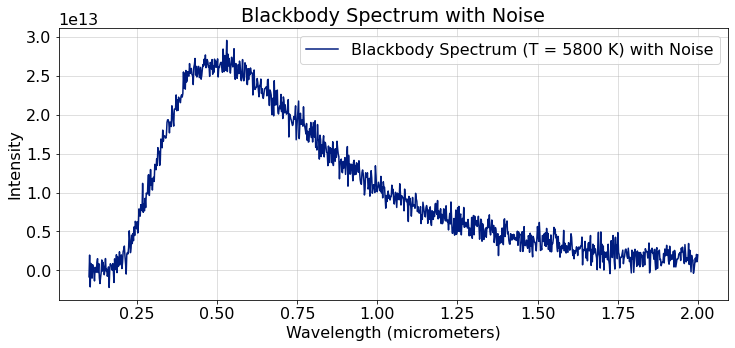

In [11]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 16})
plt.style.use('seaborn-dark-palette')

def planck_radiation(wavelength, temperature):
    """
    Calculate the intensity of radiation from a blackbody at a given temperature.

    Parameters:
    - wavelength: Wavelength values (in meters).
    - temperature: Temperature of the blackbody (in Kelvin).

    Returns:
    - intensity: Intensity of radiation at each wavelength.
    """
    h = 6.626e-34  # Planck's constant (Joule second)
    c = 3.0e8      # Speed of light (meters per second)
    k = 1.38e-23   # Boltzmann constant (Joules per Kelvin)

    intensity = (2 * h * c**2 / wavelength**5) / (np.exp((h * c) / (wavelength * k * temperature)) - 1)
    return intensity

# Generate wavelength values (in meters)
wavelength_values = np.linspace(1e-7, 2e-6, 1000)

# Set the temperature of the blackbody (in Kelvin)
temperature = 5800  # Approximate temperature of the Sun

# Calculate the blackbody spectrum
spectrum = planck_radiation(wavelength_values, temperature)

# Add noise to the spectrum
NOISE_LEVEL = 10
noise = np.random.normal(0, NOISE_LEVEL*1e11, spectrum.shape)
noisy_spectrum = spectrum + noise

# Plot the blackbody spectrum with noise
plt.figure(figsize=(12,5))
plt.plot(wavelength_values * 1e6, noisy_spectrum, label=f'Blackbody Spectrum (T = {temperature} K) with Noise')
plt.xlabel('Wavelength (micrometers)')
plt.ylabel('Intensity')
plt.grid(alpha = 0.5)
plt.title('Blackbody Spectrum with Noise')
plt.legend()
plt.show()

So now let's try and figure out the temperature in a few different ways.

Why don't we start by taking the maximum pixel and using Wiens Law?

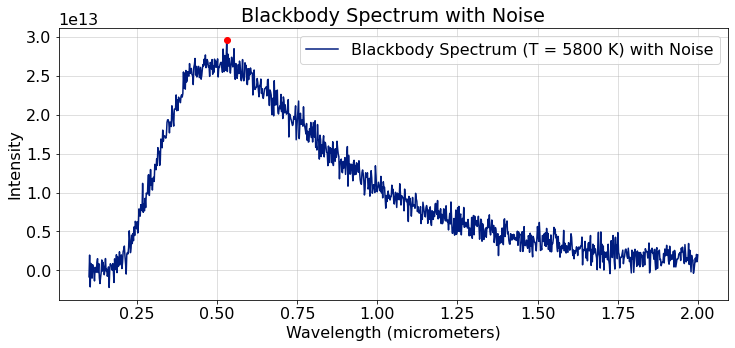

5467.793311921406
Wien's Law temperature = 5467.79K


In [19]:
max_index = np.where(noisy_spectrum == np.max(noisy_spectrum))
max_wavelength = wavelength_values[max_index][0]

def wien_law_temperature(wavelength_max):
    """
    Calculate the temperature of a blackbody using Wien's Law.

    Parameters:
    - wavelength_max: Wavelength at which the emission is maximized (in meters).

    Returns:
    - temperature: Temperature of the blackbody (in Kelvin).
    """
    b = 2.897e-3  # Wien's displacement constant in meters per Kelvin
    temperature = b / wavelength_max
    return temperature

plt.figure(figsize=(12,5))
plt.plot(wavelength_values * 1e6, noisy_spectrum, label=f'Blackbody Spectrum (T = {temperature} K) with Noise')
plt.plot(max_wavelength* 1e6, noisy_spectrum[max_index], 'o', color = 'r')
plt.xlabel('Wavelength (micrometers)')
plt.ylabel('Intensity')
plt.grid(alpha = 0.5)
plt.title('Blackbody Spectrum with Noise')
plt.legend()
plt.show()

print(f"Wien's Law temperature = {wien_law_temperature(max_wavelength):.2f}K")

How about now what if I use a polynomial fit to smooth it all out

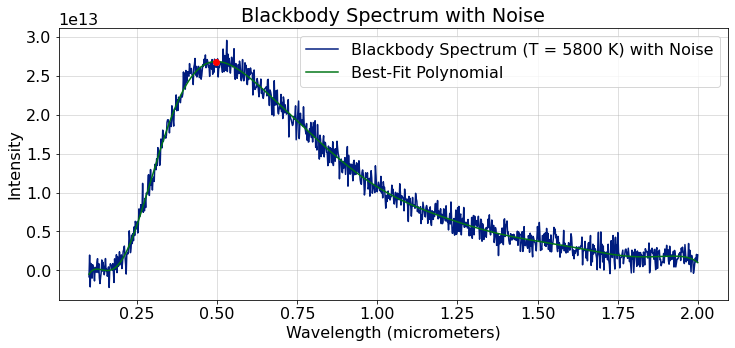

Wien's Law temperature = 5823.14K


In [28]:
p = np.poly1d(np.polyfit(wavelength_values,noisy_spectrum,15))

max_index = np.where(p(wavelength_values) == np.max(p(wavelength_values)))
max_wavelength = wavelength_values[max_index][0]

plt.figure(figsize=(12,5))
plt.plot(wavelength_values * 1e6, noisy_spectrum, label=f'Blackbody Spectrum (T = {temperature} K) with Noise')
plt.plot(wavelength_values * 1e6, p(wavelength_values), label=f'Best-Fit Polynomial')
plt.plot(max_wavelength* 1e6, noisy_spectrum[max_index], 'o', color = 'r')
plt.xlabel('Wavelength (micrometers)')
plt.ylabel('Intensity')
plt.grid(alpha = 0.5)
plt.title('Blackbody Spectrum with Noise')
plt.legend()
plt.show()

print(f"Wien's Law temperature = {wien_law_temperature(max_wavelength):.2f}K")

So here we got a better answer using the polynomial fitting, but what did it really do? Is this a physics informed model? What can we get actually out using this model?

Let's try again using the real blackbody model that the data came from

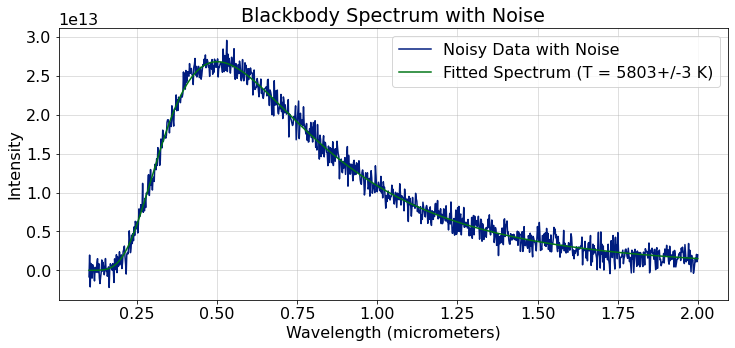

Fitted Temperature = 5803+/-3K


In [35]:
from scipy.optimize import curve_fit
from uncertainties import ufloat
initial_guess = [5000]  # Initial guess for the temperature
fit_params, covariance = curve_fit(planck_radiation, wavelength_values, noisy_spectrum, p0=initial_guess)

# Extract the fitted temperature
fitted_temperature = ufloat(fit_params[0], np.sqrt(covariance[0,0]))
plt.figure(figsize=(12,5))
plt.plot(wavelength_values * 1e6, noisy_spectrum, label='Noisy Data with Noise')
plt.plot(wavelength_values * 1e6, planck_radiation(wavelength_values, fitted_temperature.n), label=f'Fitted Spectrum (T = {fitted_temperature:.0f} K)')
plt.xlabel('Wavelength (micrometers)')
plt.ylabel('Intensity')
plt.grid(alpha = 0.5)
plt.title('Blackbody Spectrum with Noise')
plt.legend()
plt.show()

print(f"Fitted Temperature = {fitted_temperature:.0f}K")

What we have learned is that there is a big difference between polynomial smoothing and physics informed models. Now let's see what the R-squared metric tells us:

In [39]:
def compute_r2(data, fit):
    # Calculate the residuals
    residuals = data - fit

    # Calculate the total sum of squares (TSS) and residual sum of squares (RSS)
    TSS = np.sum((data - np.mean(data))**2)
    RSS = np.sum(residuals**2)

    # Calculate R-squared
    r_squared = 1 - (RSS / TSS)

    return r_squared

r_2_polynomial = compute_r2(noisy_spectrum, p(wavelength_values))
r_2_blackbody = compute_r2(noisy_spectrum, planck_radiation(wavelength_values, fitted_temperature.n))


print(f"R-square for Polynomial Fit {r_2_polynomial:.5f}")
print(f"R-square for Blackbody Fit {r_2_blackbody:.5f}")

R-square for Polynomial Fit 0.98648
R-square for Blackbody Fit 0.98625


Brief class discussion about what happened here. What is the R-squared telling you, what makes an R-squared high? How high is high enough?

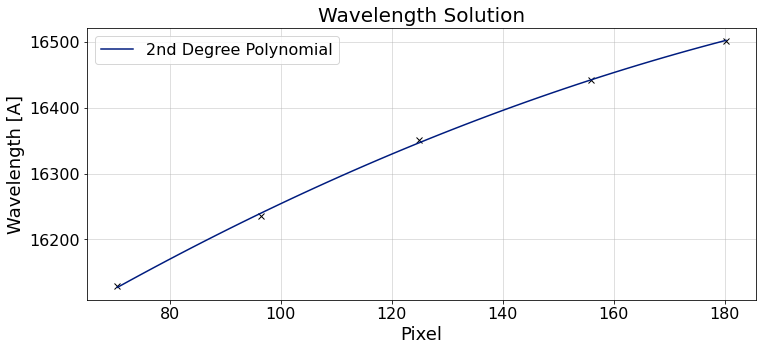

Measured Velocity 512.36+/-51.62


In [45]:
from uncertainties import correlated_values

x = np.load("./Lab3-fall2022/OH_x.npy")
y = np.load("./Lab3-fall2022/OH_y.npy")

# Fit 2nd degree polynomial (quadratic)
coefficients_2nd, cov_matrix = np.polyfit(x, y, 2, cov = True)
poly_2nd = np.poly1d(coefficients_2nd)
coeffs_uncert = correlated_values(coefficients_2nd, cov_matrix)

plt.figure(figsize=(12,5))
plt.plot(x,y, 'x', color = 'k')
plt.grid(alpha = 0.5)
plt.plot(np.linspace(np.min(x), np.max(x)), poly_2nd(np.linspace(np.min(x), np.max(x))), label='2nd Degree Polynomial Fit')
plt.legend()
plt.ylabel("Wavelength [A]", size= 18)
plt.xlabel("Pixel", size= 18)
plt.title("Wavelength Solution", size = 20)
plt.show()


line_measured_index = ufloat(165.56, 0.1) # assume 0.1 pixels of error
line_redshifted = coeffs_uncert[0] * line_measured_index**2 + coeffs_uncert[1] * line_measured_index + coeffs_uncert[2] 
line_rest = 16439.981
c = 299792.458 #km/s
velocity = (line_redshifted - line_rest)/line_rest * c

print(f"Measured Velocity {velocity:.2f}")